In [1]:
%pip install pandas numpy matplotlib scikit-learn nltk joblib

Note: you may need to restart the kernel to use updated packages.


In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt

# Machine learning
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_squared_log_error
)

# Dataset acquisition
import kagglehub

# File management
from pathlib import Path
import joblib

# Other utilities
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
from pathlib import Path
import shutil

src = Path.home() / "Downloads" / "kaggle.json"
dst = Path.home() / ".kaggle" / "kaggle.json"
dst.parent.mkdir(exist_ok=True)
if src.exists():
    shutil.copy(src, dst)
    print("Copied to {dst}")
else:
    print("Kaggle.json not found in Downloads")

Copied to {dst}


In [4]:
from pathlib import Path
import kagglehub

# Download the Kaggle dataset
data_path = kagglehub.dataset_download(
    "suraj520/customer-support-ticket-dataset"
)

data_path = Path(data_path)

print("Dataset downloaded successfully!")
print("Dataset location:", data_path)

Dataset downloaded successfully!
Dataset location: C:\Users\jabul\.cache\kagglehub\datasets\suraj520\customer-support-ticket-dataset\versions\1


In [6]:
csv_files = list(data_path.rglob("*.csv"))

if not csv_files:
    raise FileNotFoundError(
        "No CSV file found. Download and extract the dataset "
        "into the project's data folder."
    )

print("Available CSV files:")
for file in csv_files:
    print(file.name)

# Load the first CSV file
df = pd.read_csv(csv_files[0])

print("\nDataset loaded successfully!")
print("Shape:", df.shape)

df.head()

Available CSV files:
customer_support_tickets.csv

Dataset loaded successfully!
Shape: (8469, 17)


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchase...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,I'm facing a problem with my {product_purchase...,Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,I'm having an issue with the {product_purchase...,Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchase...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [7]:
# Inspect column names
print("Columns:")
print(df.columns.tolist())

# Dataset information
df.info()

# Missing values
print("\nMissing values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate records:", df.duplicated().sum())

# Statistical overview
df.describe(include="all").T

Columns:
['Ticket ID', 'Customer Name', 'Customer Email', 'Customer Age', 'Customer Gender', 'Product Purchased', 'Date of Purchase', 'Ticket Type', 'Ticket Subject', 'Ticket Description', 'Ticket Status', 'Resolution', 'Ticket Priority', 'Ticket Channel', 'First Response Time', 'Time to Resolution', 'Customer Satisfaction Rating']
<class 'pandas.DataFrame'>
RangeIndex: 8469 entries, 0 to 8468
Data columns (total 17 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Ticket ID                     8469 non-null   int64  
 1   Customer Name                 8469 non-null   str    
 2   Customer Email                8469 non-null   str    
 3   Customer Age                  8469 non-null   int64  
 4   Customer Gender               8469 non-null   str    
 5   Product Purchased             8469 non-null   str    
 6   Date of Purchase              8469 non-null   str    
 7   Ticket Type                   8469

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Ticket ID,8469.0,NaN,NaN,NaN,4235.0,2444.934048,1.0,2118.0,4235.0,6352.0,8469.0
Customer Name,8469,8028,Michael Garcia,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Email,8469,8320,asmith@example.com,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer Age,8469.0,NaN,NaN,NaN,44.026804,15.296112,18.0,31.0,44.0,57.0,70.0
Customer Gender,8469,3,Male,2896,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Product Purchased,8469,42,Canon EOS,240,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Purchase,8469,730,2020-10-21,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Type,8469,5,Refund request,1752,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Subject,8469,16,Refund request,576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ticket Description,8469,8077,I'm having an issue with the {product_purchase...,25,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
print("Ticket types:")
print(df["Ticket Type"].value_counts())

print("\nTicket priorities:")
print(df["Ticket Priority"].value_counts())

Ticket types:
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Ticket priorities:
Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64


In [15]:
import re

def clean_text(text):

    if pd.isna(text):
        return ""

    text = str(text).lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+", "", text)

    # Remove email addresses
    text = re.sub(r"\S+@\S+", "", text)

    # Remove punctuation and numbers
    text = re.sub(r"[^a-z\s]", " ", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text

In [16]:
import re
import nltk
from nltk.corpus import stopwords

In [17]:
# Combine subject and description
df["Ticket Text"] = (
    df["Ticket Subject"].fillna("").astype(str)
    + " "
    + df["Ticket Description"].fillna("").astype(str)
)

# Clean combined text
df["Cleaned Text"] = df["Ticket Text"].apply(clean_text)

df[["Ticket Text", "Cleaned Text"]].head()

,Ticket Text,Cleaned Text
0,Product setup I'm having an issue with the {pr...,product setup i m having an issue with the pro...
1,Peripheral compatibility I'm having an issue w...,peripheral compatibility i m having an issue w...
2,Network problem I'm facing a problem with my {...,network problem i m facing a problem with my p...
3,Account access I'm having an issue with the {p...,account access i m having an issue with the pr...
4,Data loss I'm having an issue with the {produc...,data loss i m having an issue with the product...


In [18]:
# Remove records with missing target labels
df = df.dropna(
    subset=["Ticket Type", "Ticket Priority"]
).copy()

# Remove records with empty text
df = df[df["Cleaned Text"].str.strip() != ""].copy()

# Input features
X = df["Cleaned Text"]

# Two classification targets
y_category = df["Ticket Type"].astype(str)
y_priority = df["Ticket Priority"].astype(str)

print("Total usable records:", len(df))

print("\nCategory classes:")
print(y_category.value_counts())

print("\nPriority classes:")
print(y_priority.value_counts())

Total usable records: 8469

Category classes:
Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64

Priority classes:
Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64


In [20]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_category_train, y_category_test = train_test_split(
    X,
    y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

# Use the same split indices for priority prediction
train_indices = X_train.index
test_indices = X_test.index

y_priority_train = y_priority.loc[train_indices]
y_priority_test = y_priority.loc[test_indices]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 6775
Testing records: 1694


In [23]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC

In [24]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ),

    "Naive Bayes": MultinomialNB(),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    )
}

In [25]:
def train_and_evaluate(X_train, X_test, y_train, y_test, task_name):

    results = []
    trained_models = {}

    for model_name, classifier in models.items():

        pipeline = Pipeline([
            (
                "tfidf",
                TfidfVectorizer(
                    max_features=10000,
                    ngram_range=(1, 2),
                    min_df=2,
                    max_df=0.95,
                    sublinear_tf=True
                )
            ),
            ("classifier", classifier)
        ])

        # Train
        pipeline.fit(X_train, y_train)

        # Predict
        predictions = pipeline.predict(X_test)

        # Evaluate
        accuracy = accuracy_score(y_test, predictions)

        precision = precision_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        recall = recall_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        f1 = f1_score(
            y_test,
            predictions,
            average="macro",
            zero_division=0
        )

        results.append({
            "Task": task_name,
            "Model": model_name,
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1 Score": f1
        })

        trained_models[model_name] = pipeline

        print(f"\n{task_name} - {model_name}")
        print(classification_report(
            y_test,
            predictions,
            zero_division=0
        ))

    return pd.DataFrame(results), trained_models

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    ConfusionMatrixDisplay
)

In [31]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer

category_results, category_models = train_and_evaluate(
    X_train,
    X_test,
    y_category_train,
    y_category_test,
    "Ticket Category"
)

category_results


Ticket Category - Logistic Regression
                      precision    recall  f1-score   support

     Billing inquiry       0.18      0.20      0.19       327
Cancellation request       0.20      0.20      0.20       339
     Product inquiry       0.22      0.25      0.24       328
      Refund request       0.22      0.20      0.21       351
     Technical issue       0.23      0.21      0.22       349

            accuracy                           0.21      1694
           macro avg       0.21      0.21      0.21      1694
        weighted avg       0.21      0.21      0.21      1694


Ticket Category - Naive Bayes
                      precision    recall  f1-score   support

     Billing inquiry       0.16      0.10      0.12       327
Cancellation request       0.21      0.19      0.20       339
     Product inquiry       0.20      0.16      0.17       328
      Refund request       0.21      0.28      0.24       351
     Technical issue       0.21      0.27      0.24       

,Task,Model,Accuracy,Precision,Recall,F1 Score
0,Ticket Category,Logistic Regression,0.211334,0.211926,0.211650,0.211221
1,Ticket Category,Naive Bayes,0.202479,0.198141,0.200477,0.195354
2,Ticket Category,Linear SVM,0.204841,0.204924,0.205009,0.204797


In [32]:
priority_results, priority_models = train_and_evaluate(
    X_train,
    X_test,
    y_priority_train,
    y_priority_test,
    "Ticket Priority"
)

priority_results


Ticket Priority - Logistic Regression
              precision    recall  f1-score   support

    Critical       0.25      0.24      0.25       441
        High       0.29      0.28      0.29       424
         Low       0.21      0.25      0.23       375
      Medium       0.30      0.28      0.29       454

    accuracy                           0.26      1694
   macro avg       0.26      0.26      0.26      1694
weighted avg       0.26      0.26      0.26      1694


Ticket Priority - Naive Bayes
              precision    recall  f1-score   support

    Critical       0.23      0.24      0.24       441
        High       0.28      0.19      0.23       424
         Low       0.22      0.23      0.23       375
      Medium       0.28      0.33      0.30       454

    accuracy                           0.25      1694
   macro avg       0.25      0.25      0.25      1694
weighted avg       0.25      0.25      0.25      1694


Ticket Priority - Linear SVM
              precision    rec

,Task,Model,Accuracy,Precision,Recall,F1 Score
0,Ticket Priority,Logistic Regression,0.262692,0.263152,0.262067,0.262251
1,Ticket Priority,Naive Bayes,0.251476,0.252278,0.249722,0.248224
2,Ticket Priority,Linear SVM,0.260331,0.259864,0.259346,0.259334


In [33]:
all_results = pd.concat(
    [category_results, priority_results],
    ignore_index=True
)

print(all_results.sort_values(
    by=["Task", "F1 Score"],
    ascending=[True, False]
).to_string(index=False))

           Task               Model  Accuracy  Precision   Recall  F1 Score
Ticket Category Logistic Regression  0.211334   0.211926 0.211650  0.211221
Ticket Category          Linear SVM  0.204841   0.204924 0.205009  0.204797
Ticket Category         Naive Bayes  0.202479   0.198141 0.200477  0.195354
Ticket Priority Logistic Regression  0.262692   0.263152 0.262067  0.262251
Ticket Priority          Linear SVM  0.260331   0.259864 0.259346  0.259334
Ticket Priority         Naive Bayes  0.251476   0.252278 0.249722  0.248224


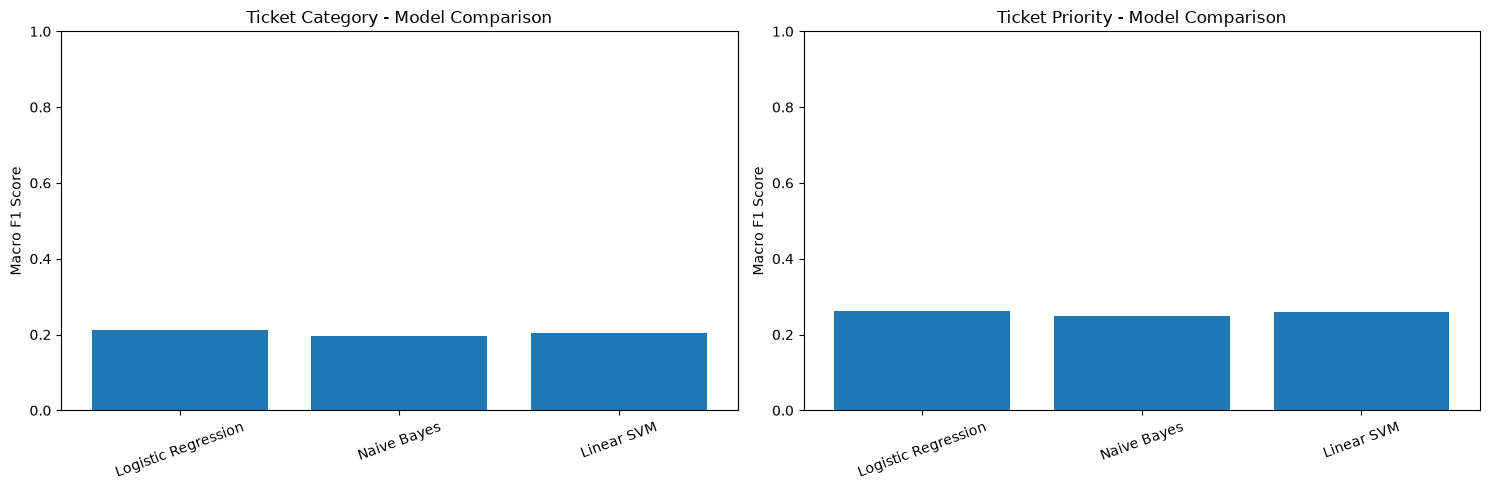

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

for ax, task in zip(
    axes,
    ["Ticket Category", "Ticket Priority"]
):

    task_data = all_results[
        all_results["Task"] == task
    ]

    ax.bar(
        task_data["Model"],
        task_data["F1 Score"]
    )

    ax.set_title(f"{task} - Model Comparison")
    ax.set_ylabel("Macro F1 Score")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

In [35]:
best_category_name = (
    category_results
    .sort_values("F1 Score", ascending=False)
    .iloc[0]["Model"]
)

best_priority_name = (
    priority_results
    .sort_values("F1 Score", ascending=False)
    .iloc[0]["Model"]
)

best_category_model = category_models[best_category_name]
best_priority_model = priority_models[best_priority_name]

print("Best category model:", best_category_name)
print("Best priority model:", best_priority_name)

Best category model: Logistic Regression
Best priority model: Logistic Regression


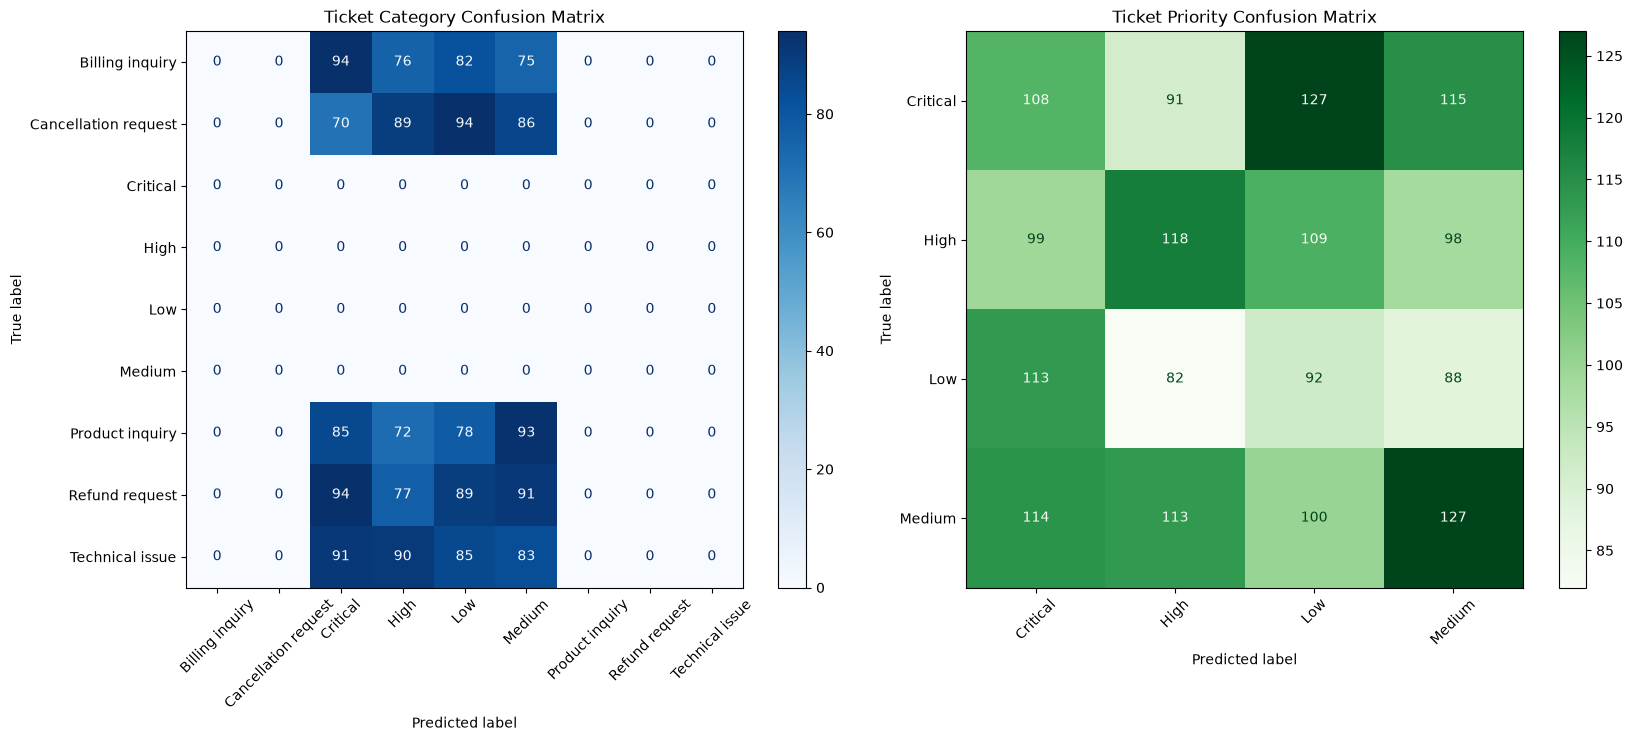

In [36]:
category_predictions = best_category_model.predict(X_test)
priority_predictions = best_priority_model.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(17, 7))

ConfusionMatrixDisplay.from_predictions(
    y_category_test,
    category_predictions,
    xticks_rotation=45,
    cmap="Blues",
    ax=axes[0]
)

axes[0].set_title("Ticket Category Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_priority_test,
    priority_predictions,
    xticks_rotation=45,
    cmap="Greens",
    ax=axes[1]
)

axes[1].set_title("Ticket Priority Confusion Matrix")

plt.tight_layout()
plt.show()

In [37]:
print("CATEGORY CLASSIFICATION REPORT")
print(
    classification_report(
        y_category_test,
        category_predictions,
        zero_division=0
    )
)

print("\nPRIORITY CLASSIFICATION REPORT")
print(
    classification_report(
        y_priority_test,
        priority_predictions,
        zero_division=0
    )
)

CATEGORY CLASSIFICATION REPORT
                      precision    recall  f1-score   support

     Billing inquiry       0.00      0.00      0.00     327.0
Cancellation request       0.00      0.00      0.00     339.0
            Critical       0.00      0.00      0.00       0.0
                High       0.00      0.00      0.00       0.0
                 Low       0.00      0.00      0.00       0.0
              Medium       0.00      0.00      0.00       0.0
     Product inquiry       0.00      0.00      0.00     328.0
      Refund request       0.00      0.00      0.00     351.0
     Technical issue       0.00      0.00      0.00     349.0

            accuracy                           0.00    1694.0
           macro avg       0.00      0.00      0.00    1694.0
        weighted avg       0.00      0.00      0.00    1694.0


PRIORITY CLASSIFICATION REPORT
              precision    recall  f1-score   support

    Critical       0.25      0.24      0.25       441
        High       

In [39]:
MODEL_DIR = Path.home() / "CustomerSupportNLP" / "models"
OUTPUT_DIR = Path.home() / "CustomerSupportNLP" / "outputs"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [40]:
def classify_ticket(ticket_subject, ticket_description):

    ticket_text = ticket_subject + " " + ticket_description

    cleaned_ticket = clean_text(ticket_text)

    category_prediction = best_category_model.predict(
        [cleaned_ticket]
    )[0]

    priority_prediction = best_priority_model.predict(
        [cleaned_ticket]
    )[0]

    return {
        "Ticket Subject": ticket_subject,
        "Predicted Category": category_prediction,
        "Predicted Priority": priority_prediction
    }

In [41]:
new_ticket = classify_ticket(
    ticket_subject="Unable to access my account",
    ticket_description=(
        "I have tried logging in several times, "
        "but the system keeps rejecting my password. "
        "I need assistance accessing my account."
    )
)

for key, value in new_ticket.items():
    print(f"{key}: {value}")

Ticket Subject: Unable to access my account
Predicted Category: Critical
Predicted Priority: Critical


In [42]:
sample_tickets = [
    {
        "subject": "Payment was deducted twice",
        "description": "I was charged twice for one purchase."
    },
    {
        "subject": "Application is running slowly",
        "description": "The dashboard takes a long time to load."
    },
    {
        "subject": "Request for product information",
        "description": "I would like to know more about the available features."
    }
]

for ticket in sample_tickets:

    result = classify_ticket(
        ticket["subject"],
        ticket["description"]
    )

    print("\n", result)


 {'Ticket Subject': 'Payment was deducted twice', 'Predicted Category': 'Critical', 'Predicted Priority': 'Critical'}

 {'Ticket Subject': 'Application is running slowly', 'Predicted Category': 'Medium', 'Predicted Priority': 'Medium'}

 {'Ticket Subject': 'Request for product information', 'Predicted Category': 'High', 'Predicted Priority': 'High'}


In [43]:
print("=" * 55)
print("CUSTOMER SUPPORT TICKET CLASSIFICATION SYSTEM")
print("=" * 55)

print("\nSelected models:")
print("Category model:", best_category_name)
print("Priority model:", best_priority_name)

print("\nCategory model performance:")
print(
    category_results[
        category_results["Model"] == best_category_name
    ][["Accuracy", "Precision", "Recall", "F1 Score"]]
    .round(4)
    .to_string(index=False)
)

print("\nPriority model performance:")
print(
    priority_results[
        priority_results["Model"] == best_priority_name
    ][["Accuracy", "Precision", "Recall", "F1 Score"]]
    .round(4)
    .to_string(index=False)
)

print("\nBusiness application:")
print("- Automatically categorize incoming support tickets.")
print("- Predict ticket priority to support queue organization.")
print("- Help support teams identify recurring customer issues.")
print("- Reduce manual ticket sorting.")
print("=" * 55)

CUSTOMER SUPPORT TICKET CLASSIFICATION SYSTEM

Selected models:
Category model: Logistic Regression
Priority model: Logistic Regression

Category model performance:
 Accuracy  Precision  Recall  F1 Score
   0.2113     0.2119  0.2117    0.2112

Priority model performance:
 Accuracy  Precision  Recall  F1 Score
   0.2627     0.2632  0.2621    0.2623

Business application:
- Automatically categorize incoming support tickets.
- Predict ticket priority to support queue organization.
- Help support teams identify recurring customer issues.
- Reduce manual ticket sorting.
